(6607, 20)
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gen

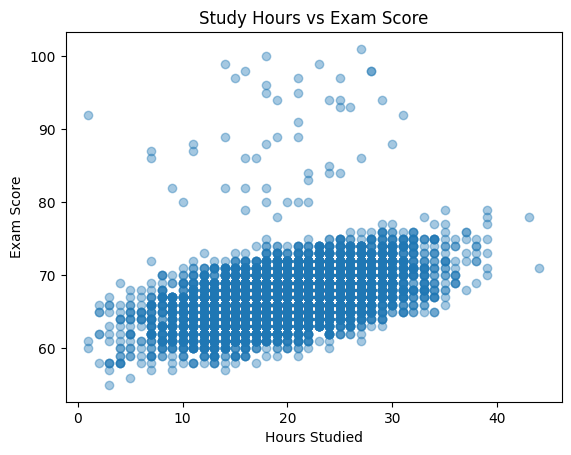

MAE : 2.4475687452945643
RMSE: 3.294832513010839
R2  : 0.2319868674542106


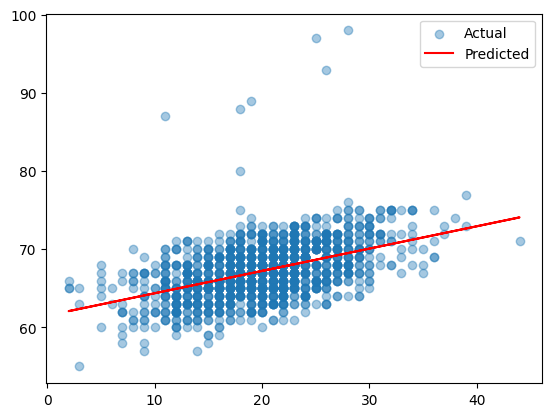

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


df = pd.read_csv("StudentPerformanceFactors.csv")
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())

df = df.drop_duplicates()
df = df.dropna(subset=["Hours_Studied", "Exam_Score"])

plt.scatter(df["Hours_Studied"], df["Exam_Score"], alpha=0.4)
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")
plt.show()


X = df[["Hours_Studied"]]
y = df["Exam_Score"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("MAE :", mean_absolute_error(y_test, pred))
print("RMSE:", mean_squared_error(y_test, pred) ** 0.5)
print("R2  :", r2_score(y_test, pred))

plt.scatter(X_test, y_test, alpha=0.4, label="Actual")
plt.plot(X_test, pred, color="red", label="Predicted")
plt.legend()
plt.show()

In [3]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

for col in ["Teacher_Quality", "Parental_Education_Level", "Distance_from_Home"]:
    df[col] = df[col].fillna(df[col].mode()[0])

train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
y_train = train_df["Exam_Score"]
y_test = test_df["Exam_Score"]

def run(name, model, cols):
    Xtr = pd.get_dummies(train_df[cols])
    Xte = pd.get_dummies(test_df[cols]).reindex(columns=Xtr.columns, fill_value=0)
    model.fit(Xtr, y_train)
    p = model.predict(Xte)
    print(f"{name:32} MAE={mean_absolute_error(y_test, p):.2f}  "
          f"RMSE={mean_squared_error(y_test, p) ** 0.5:.2f}  R2={r2_score(y_test, p):.3f}")

hours = ["Hours_Studied"]
some = ["Hours_Studied", "Attendance", "Sleep_Hours", "Previous_Scores",
        "Tutoring_Sessions", "Physical_Activity"]
all_cols = [c for c in df.columns if c != "Exam_Score"]

run("Linear (Hours only)", LinearRegression(), hours)
run("Polynomial deg 2 (Hours)", make_pipeline(PolynomialFeatures(2), LinearRegression()), hours)
run("Polynomial deg 3 (Hours)", make_pipeline(PolynomialFeatures(3), LinearRegression()), hours)
run("Linear (6 numeric features)", LinearRegression(), some)
run("Linear (all features)", LinearRegression(), all_cols)

Linear (Hours only)              MAE=2.45  RMSE=3.29  R2=0.232
Polynomial deg 2 (Hours)         MAE=2.44  RMSE=3.29  R2=0.233
Polynomial deg 3 (Hours)         MAE=2.44  RMSE=3.29  R2=0.233
Linear (6 numeric features)      MAE=1.27  RMSE=2.25  R2=0.642
Linear (all features)            MAE=0.45  RMSE=1.80  R2=0.770
